# Trabalho 4 — Mineração de Dados / Regras de Associação
## Análise de Cestas de Compras



## **1. Carregamento e validação da base**

A base possui representação binária:

- cada **linha** representa uma transação;
- cada **coluna** representa um produto;
- `1` indica presença do produto;
- `0` indica ausência.

**Verificar se a base está estruturalmente adequada:**
- valores ausentes
- atributos não binários
- transações vazias
- itens sem ocorrência.

In [2]:
# ============================================================
# 1. CARREGAMENTO E VALIDAÇÃO DA BASE
# ============================================================

#!pip install -q mlxtend

import os
import math
import warnings
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

warnings.filterwarnings("ignore", category=DeprecationWarning)

# Ajuste geral para melhorar a leitura dos gráficos na apresentação
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11
})

# 1.1 Conexão com o Google Drive
drive.mount("/content/drive")

# 1.2 Caminho da base
caminho_arquivo = (
    "/content/drive/MyDrive/Trabalho4_Regras_Associacao/"
    "trabalho4_dados_4 - trabalho4_dados_4.csv"
)

# 1.3 Validação do caminho e carga
if not os.path.exists(caminho_arquivo):
    raise FileNotFoundError(
        "Arquivo não encontrado. Verifique se a base está na pasta:\n"
        "/content/drive/MyDrive/Trabalho4_Regras_Associacao/"
    )

dados = pd.read_csv(caminho_arquivo)

print(f"BASE {caminho_arquivo} CARREGADA")
print("-" * 55)
print(f"Transações: {dados.shape[0]}")
print(f"Produtos:   {dados.shape[1]}")
display(dados.head())

# 1.4 Validações estruturais
total_ausentes = dados.isnull().sum().sum()

colunas_nao_binarias = [
    coluna for coluna in dados.columns
    if not set(dados[coluna].dropna().unique()).issubset({0, 1})
]

transacoes_vazias = (dados.sum(axis=1) == 0).sum()
itens_sem_ocorrencia = dados.columns[dados.sum(axis=0) == 0].tolist()

print("\nVALIDAÇÃO")
print("-" * 55)
print(f"Valores ausentes:     {total_ausentes}")
print(f"Colunas não binárias: {len(colunas_nao_binarias)}")
print(f"Transações vazias:    {transacoes_vazias}")
print(f"Itens sem ocorrência: {len(itens_sem_ocorrencia)}")

Mounted at /content/drive
BASE /content/drive/MyDrive/Trabalho4_Regras_Associacao/trabalho4_dados_4 - trabalho4_dados_4.csv CARREGADA
-------------------------------------------------------
Transações: 3882
Produtos:   132


,ABSORVENTE,ACETONA,ACHOCOLATADO,ACUCAR,ADOCANTE,AGUA_OXIGENADA,AGUA,ALGODAO,AMENDOIN,AMONIA,...,TOALHA_DE_BANHO,TOALHA_DE_ROSTO,TORNEIRA,TORRADA,TRIGO_DE_QUIBE,UTEN_COZINHA,VELA_DE_FILTRO,VELA,VERDURAS,VINAGRE
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



VALIDAÇÃO
-------------------------------------------------------
Valores ausentes:     0
Colunas não binárias: 0
Transações vazias:    0
Itens sem ocorrência: 0


**Transações com conteúdo idêntico não foram removidas, pois cestas iguais podem representar compras distintas.**

## **2. Análise das transações**

- quantidade de produtos por transação;
- distribuição do tamanho das cestas;
- produtos mais frequentes;

TAMANHO DAS CESTAS
-------------------------------------------------------
Média:   3.46
Mediana: 2
Mínimo:  1
Máximo:  57
Até 4 itens: 80.7%

10 PRODUTOS MAIS FREQUENTES
-------------------------------------------------------


,Produto,Frequência,Suporte (%)
0,BISCOITO,879,22.64
1,PAES,640,16.49
2,REFRIGERANTE,636,16.38
3,LEGUMES,635,16.36
4,PROD_LIMPEZA,527,13.58
5,SUCO,398,10.25
6,QUEIJOS,389,10.02
7,FRUTAS,340,8.76
8,LEITE,337,8.68
9,ESPECIARIAS,320,8.24


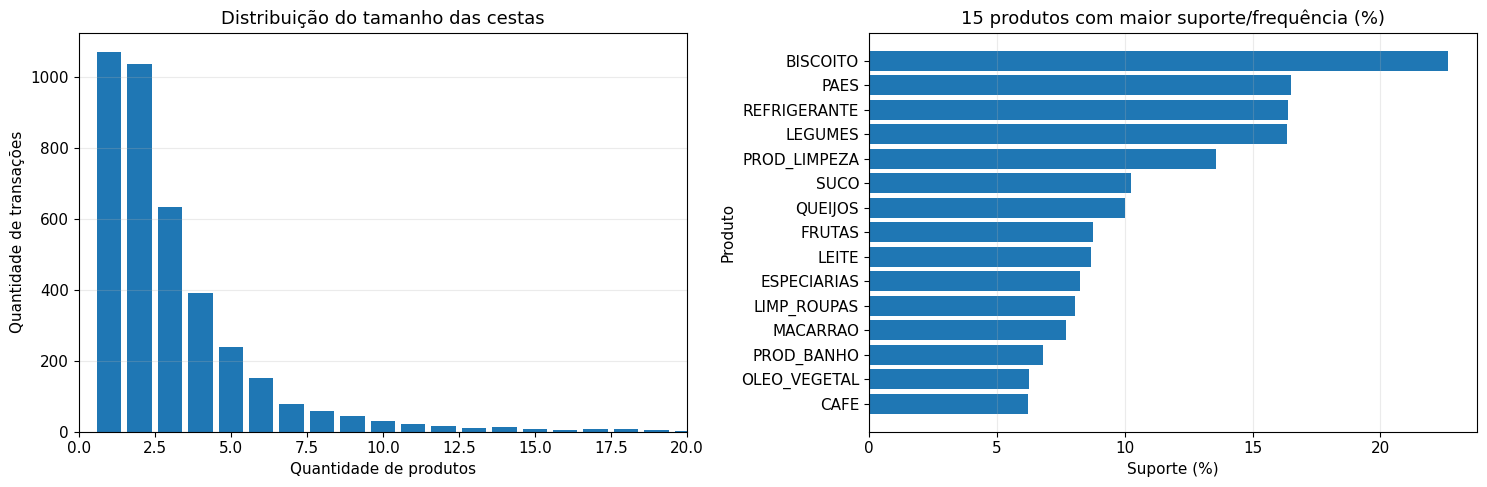

In [3]:
# ============================================================
# 2. ANÁLISE EXPLORATÓRIA
# ============================================================

# Quantidade de produtos por transação
itens_por_transacao = dados.sum(axis=1)

# Frequência e suporte individual
frequencia_itens = dados.sum(axis=0).sort_values(ascending=False)
suporte_itens = frequencia_itens / len(dados)

tabela_itens = pd.DataFrame({
    "Produto": frequencia_itens.index,
    "Frequência": frequencia_itens.values,
    "Suporte (%)": suporte_itens.values * 100
})

print("TAMANHO DAS CESTAS")
print("-" * 55)
print(f"Média:   {itens_por_transacao.mean():.2f}")
print(f"Mediana: {itens_por_transacao.median():.0f}")
print(f"Mínimo:  {itens_por_transacao.min()}")
print(f"Máximo:  {itens_por_transacao.max()}")
print(f"Até 4 itens: {(itens_por_transacao <= 4).mean() * 100:.1f}%")

print("\n10 PRODUTOS MAIS FREQUENTES")
print("-" * 55)
display(tabela_itens.head(10).round(2))

# ------------------------------------------------------------
# VISUALIZAÇÃO CONJUNTA
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1 — Distribuição do tamanho das cestas
frequencia_cestas = itens_por_transacao.value_counts().sort_index()
axes[0].bar(frequencia_cestas.index, frequencia_cestas.values)
axes[0].set_xlim(0, 20)
axes[0].set_title("Distribuição do tamanho das cestas")
axes[0].set_xlabel("Quantidade de produtos")
axes[0].set_ylabel("Quantidade de transações")
axes[0].grid(axis="y", alpha=0.25)

# Gráfico 2 — Top 15 produtos por suporte
top15 = tabela_itens.head(15).sort_values("Suporte (%)")
axes[1].barh(top15["Produto"], top15["Suporte (%)"])
axes[1].set_title("15 produtos com maior suporte/frequência (%)")
axes[1].set_xlabel("Suporte (%)")
axes[1].set_ylabel("Produto")
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

## 3. Escolha do suporte mínimo

O **suporte** representa a **proporção de transações em que determinado item ou conjunto de itens aparece.**

Alternativas testadas: **5% · 3% · 2% · 1% · 0,5%**

O algoritmo **Apriori** encontra os conjuntos frequentes. Depois o association_rules transforma os itemsets frequentes em regras direcionais

,Suporte (%),Transações mínimas,Quantidade de itemsets
0,5.0,195,20
1,3.0,117,50
2,2.0,78,122
3,1.0,39,1075
4,0.5,20,18684


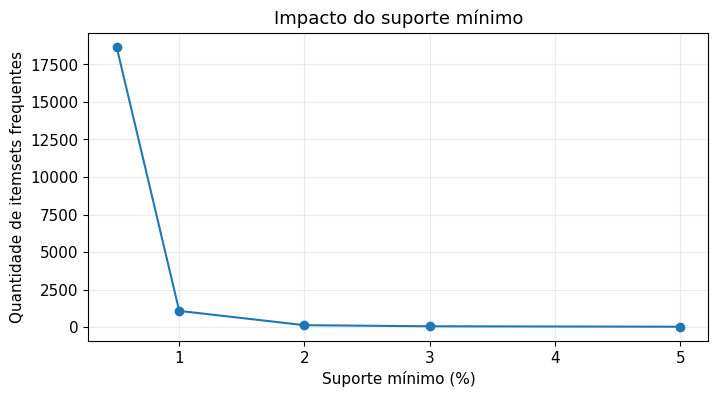

Suporte escolhido: 2%
Equivalente a pelo menos 78 transações
Itemsets frequentes encontrados: 122


In [4]:
# ============================================================
# 3. AVALIAÇÃO DO SUPORTE MÍNIMO
# ============================================================

dados_bool = dados.astype(bool)

suportes_testados = [0.05, 0.03, 0.02, 0.01, 0.005]
resultados_suporte = []

for suporte in suportes_testados:

    itemsets_teste = apriori(
        dados_bool,
        min_support=suporte,
        use_colnames=True
    )

    resultados_suporte.append({
        "Suporte (%)": suporte * 100,
        "Transações mínimas": math.ceil(suporte * len(dados)),
        "Quantidade de itemsets": len(itemsets_teste)
    })

tabela_suportes = pd.DataFrame(resultados_suporte)
display(tabela_suportes)

plt.figure(figsize=(8, 4))
plt.plot(
    tabela_suportes["Suporte (%)"],
    tabela_suportes["Quantidade de itemsets"],
    marker="o"
)
plt.title("Impacto do suporte mínimo")
plt.xlabel("Suporte mínimo (%)")
plt.ylabel("Quantidade de itemsets frequentes")
plt.grid(alpha=0.25)
plt.show()

# Suporte escolhido
min_support = 0.02

itemsets_frequentes = apriori(
    dados_bool,
    min_support=min_support,
    use_colnames=True
).sort_values("support", ascending=False).reset_index(drop=True)

print(f"Suporte escolhido: {min_support * 100:.0f}%")
print(f"Equivalente a pelo menos {math.ceil(min_support * len(dados))} transações")
print(f"Itemsets frequentes encontrados: {len(itemsets_frequentes)}")

### **Decisão: suporte mínimo de 2%**

**A escolha do suporte é um trade-off:** se for muito alto, podemos perder associações interessantes; se for muito baixo, teremos milhares de combinações pouco frequentes
A redução do suporte provoca forte crescimento no número de combinações:

| Suporte | Itemsets |
|---:|---:|
| 5% | 20 |
| 3% | 50 |
| **2%** | **122** |
| 1% | 1.075 |
| 0,5% | 18.682 |

O suporte de **2%**, equivalente a pelo menos **78 transações**, foi escolhido como ponto de equilíbrio.

Abaixo desse valor, a quantidade de combinações cresce rapidamente. Assim, mantemos padrões com presença mínima relevante sem gerar um conjunto excessivo de resultados.

**Resultado:** 122 itemsets frequentes.

### **Verificação adicional com FP-Growth**

O algoritmo principal do trabalho continua sendo o **Apriori**, gerando combinações candidatas progressivamente.

Como verificação adicional, executamos também o **FP-Growth** com o mesmo suporte mínimo.

Os dois algoritmos têm o mesmo objetivo principal: encontrar itemsets frequentes. A diferença está principalmente em como fazem a busca.

In [5]:
# ------------------------------------------------------------
# 3.1 VALIDAÇÃO DOS ITEMSETS COM FP-GROWTH
# ------------------------------------------------------------

itemsets_fp = fpgrowth(
    dados_bool,
    min_support=min_support,
    use_colnames=True
)

conjunto_apriori = set(itemsets_frequentes["itemsets"])
conjunto_fpgrowth = set(itemsets_fp["itemsets"])

print("VALIDAÇÃO APRIORI × FP-GROWTH")
print("-" * 55)
print(f"Itemsets — Apriori:   {len(conjunto_apriori)}")
print(f"Itemsets — FP-Growth: {len(conjunto_fpgrowth)}")
print(f"Mesmos itemsets:      {conjunto_apriori == conjunto_fpgrowth}")

VALIDAÇÃO APRIORI × FP-GROWTH
-------------------------------------------------------
Itemsets — Apriori:   122
Itemsets — FP-Growth: 122
Mesmos itemsets:      True


### **Resultado da validação**

Com o mesmo suporte mínimo de **2%**, Apriori e FP-Growth encontram os **mesmos 122 itemsets frequentes**.

Essa comparação funciona como uma **validação cruzada do resultado**.

## **4. Composição dos itemsets frequentes**

Eles são principalmente **produtos isolados, pares ou grupos maiores?**

Também verificamos quais combinações apresentam maior suporte.

Agrupamento dos resultados do Apriori pelo tamanho do itemset:

ITEMSETS POR TAMANHO
-------------------------------------------------------
1 item(ns): 51
2 item(ns): 70
3 item(ns): 1


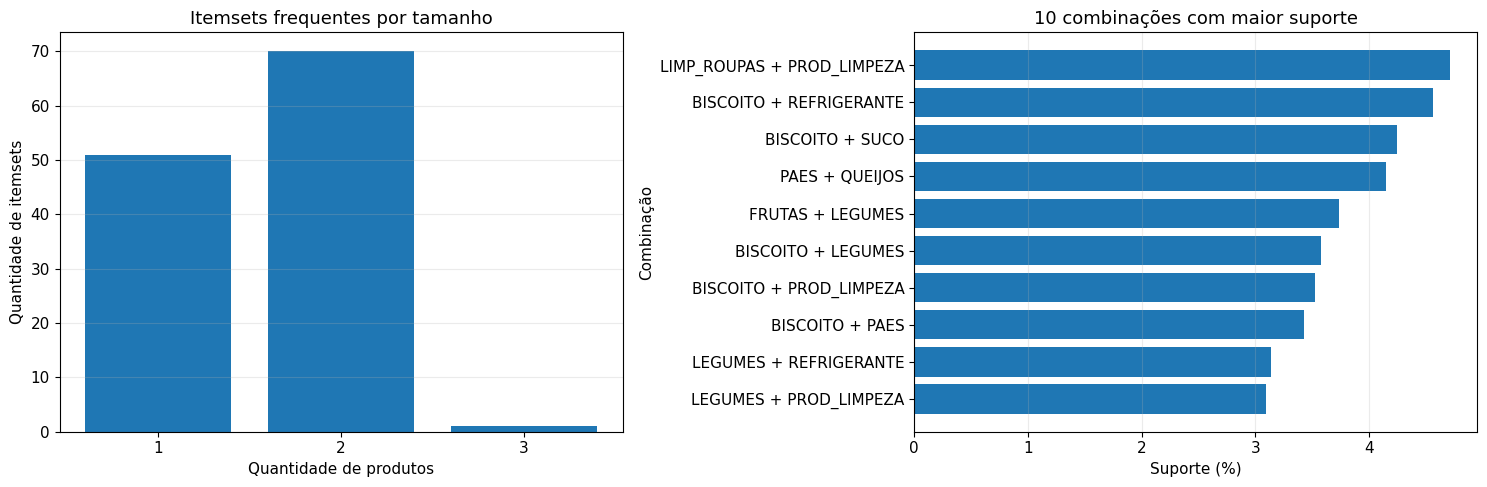

,produtos,tamanho,suporte_percentual
0,LIMP_ROUPAS + PROD_LIMPEZA,2,4.71
1,BISCOITO + REFRIGERANTE,2,4.56
2,BISCOITO + SUCO,2,4.25
3,PAES + QUEIJOS,2,4.15
4,FRUTAS + LEGUMES,2,3.74
5,BISCOITO + LEGUMES,2,3.58
6,BISCOITO + PROD_LIMPEZA,2,3.53
7,BISCOITO + PAES,2,3.43
8,LEGUMES + REFRIGERANTE,2,3.14
9,LEGUMES + PROD_LIMPEZA,2,3.09


In [6]:
# ============================================================
# 4. ANÁLISE DOS ITEMSETS FREQUENTES
# ============================================================

itemsets_frequentes["tamanho"] = (
    itemsets_frequentes["itemsets"].apply(len)
)

quantidade_por_tamanho = (
    itemsets_frequentes["tamanho"]
    .value_counts()
    .sort_index()
)
print("Agrupamento dos resultados do Apriori pelo tamanho do itemset:\n")
print("ITEMSETS POR TAMANHO")
print("-" * 55)

for tamanho, quantidade in quantidade_por_tamanho.items():
    print(f"{tamanho} item(ns): {quantidade}")

# Combinações com pelo menos dois produtos
itemsets_combinados = itemsets_frequentes[
    itemsets_frequentes["tamanho"] >= 2
].copy()

itemsets_combinados["suporte_percentual"] = (
    itemsets_combinados["support"] * 100
)

itemsets_combinados["produtos"] = (
    itemsets_combinados["itemsets"]
    .apply(lambda itens: " + ".join(sorted(itens)))
)

itemsets_combinados = itemsets_combinados.sort_values(
    "support", ascending=False
).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico 1 — quantidade por tamanho
axes[0].bar(
    quantidade_por_tamanho.index.astype(str),
    quantidade_por_tamanho.values
)
axes[0].set_title("Itemsets frequentes por tamanho")
axes[0].set_xlabel("Quantidade de produtos")
axes[0].set_ylabel("Quantidade de itemsets")
axes[0].grid(axis="y", alpha=0.25)

# Gráfico 2 — combinações com maior suporte
top10_combinacoes = itemsets_combinados.head(10).sort_values(
    "suporte_percentual"
)

axes[1].barh(
    top10_combinacoes["produtos"],
    top10_combinacoes["suporte_percentual"]
)
axes[1].set_title("10 combinações com maior suporte")
axes[1].set_xlabel("Suporte (%)")
axes[1].set_ylabel("Combinação")
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

display(
    itemsets_combinados[
        ["produtos", "tamanho", "suporte_percentual"]
    ].head(10).round(2)
)

### Resultado dos itemsets

Dos **122 itemsets frequentes**:

- **51** possuem 1 produto;
- **70** possuem 2 produtos;
- apenas **1** possui 3 produtos (produtos para lavar roupas, banho e limpeza com suporte de 2,09%).

Portanto, existem **71 combinações frequentes envolvendo mais de um produto**.

Entre os padrões de maior suporte aparecem combinações como:

**LIMP_ROUPAS + PROD_LIMPEZA**, **BISCOITO + REFRIGERANTE**, **PAES + QUEIJOS** e **FRUTAS + LEGUMES**.

Mas frequência conjunta, isoladamente, não determina a força da associação.

**Dois produtos populares podem aparecer juntos simplesmente porque ambos são muito frequentes.**

**Vamos transformar essas combinações em regras.**

## **5. Combinações para as regras de associação**

Uma regra possui a forma: **X (antecedente) → Y (consequente)**

As regras serão avaliadas pelas **três métricas** utilizadas no trabalho:

- **Suporte:** representatividade da combinação na base;
- **Confiança:** com que frequência Y aparece quando X aparece/ocorre;
- **Lift:** quanto essa associação supera o esperado caso X e Y fossem independentes.

In [7]:
# ============================================================
# 5. GERAÇÃO DAS REGRAS DE ASSOCIAÇÃO
# ============================================================

regras = association_rules(
    itemsets_frequentes,
    metric="confidence",
    min_threshold=0
)

# Nomes textuais para facilitar tabelas e gráficos
regras["antecedente"] = regras["antecedents"].apply(
    lambda itens: " + ".join(sorted(itens))
)

regras["consequente"] = regras["consequents"].apply(
    lambda itens: " + ".join(sorted(itens))
)

regras["suporte_percentual"] = regras["support"] * 100
regras["confianca_percentual"] = regras["confidence"] * 100

print(f"Quantidade total de regras geradas: {len(regras)}")

print("\nRESUMO DAS MÉTRICAS")
print("-" * 55)
display(
    regras[["support", "confidence", "lift"]]
    .describe()
    .round(4)
)

print("COMPORTAMENTO DO LIFT")
print("-" * 55)
print(f"Lift > 1: {(regras['lift'] > 1).sum()}")
print(f"Lift = 1: {(regras['lift'].round(6) == 1).sum()}")
print(f"Lift < 1: {(regras['lift'] < 1).sum()}")

Quantidade total de regras geradas: 146

RESUMO DAS MÉTRICAS
-------------------------------------------------------


,support,confidence,lift
count,146.0000,146.0000,146.0000
mean,0.0252,0.2848,3.2848
std,0.0062,0.1523,2.5777
min,0.0201,0.0887,0.9178
25%,0.0211,0.1634,1.4301
50%,0.0232,0.2556,2.3241
75%,0.0265,0.3607,4.2434
max,0.0471,1.0000,11.5193


COMPORTAMENTO DO LIFT
-------------------------------------------------------
Lift > 1: 140
Lift = 1: 0
Lift < 1: 6


**Em 100% das compras que continham creme de leite, também havia leite.**

**Não significa que creme de leite causa a compra de leite; apenas que há uma associação muito forte nessa base.**


O suporte já garante que a combinação ocorre em pelo menos 2% das transações.

A **confiança é direcional**: quando o antecedente ocorre, com que frequência o consequente também ocorre.

O **lift** complementa essa análise, medindo a **força da associação**:

Lift = 1: A e B são independentes.
Lift > 1: associação positiva.
Lift < 1: associação negativa.

**O próximo passo é reduzir o conjunto de regras analisando a confiança mínima.**

## **6. Avaliação da confiança mínima**

Mantendo apenas associações positivas (`lift > 1`), testamos diferentes limites de confiança:

**20% · 30% · 40% · 50% · 60%**

Assim como no suporte, a escolha é baseada no efeito do parâmetro sobre a quantidade de regras.

,Confiança (%),Quantidade de regras
0,20.0,89
1,30.0,60
2,40.0,26
3,50.0,9
4,60.0,4


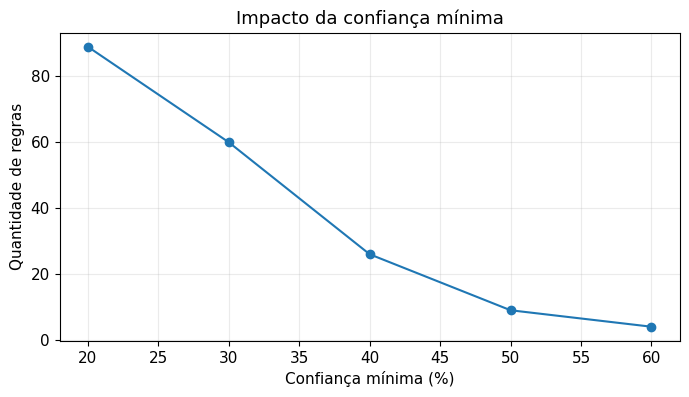

CRITÉRIOS FINAIS
-------------------------------------------------------
Suporte mínimo:    2%
Confiança mínima: 40%
Lift:             > 1
Regras selecionadas: 26


In [8]:
# ============================================================
# 6. DEFINIÇÃO DOS CRITÉRIOS DE SELEÇÃO
# ============================================================

confiancas_testadas = [0.20, 0.30, 0.40, 0.50, 0.60]
resultados_confianca = []

for confianca in confiancas_testadas:

    regras_filtradas = regras[
        (regras["confidence"] >= confianca) &
        (regras["lift"] > 1)
    ]

    resultados_confianca.append({
        "Confiança (%)": confianca * 100,
        "Quantidade de regras": len(regras_filtradas)
    })

tabela_confianca = pd.DataFrame(resultados_confianca)
display(tabela_confianca)

plt.figure(figsize=(8, 4))
plt.plot(
    tabela_confianca["Confiança (%)"],
    tabela_confianca["Quantidade de regras"],
    marker="o"
)
plt.title("Impacto da confiança mínima")
plt.xlabel("Confiança mínima (%)")
plt.ylabel("Quantidade de regras")
plt.grid(alpha=0.25)
plt.show()

# Critérios finais
min_confidence = 0.40
min_lift = 1

regras_selecionadas = regras[
    (regras["confidence"] >= min_confidence) &
    (regras["lift"] > min_lift)
].copy()

regras_selecionadas = regras_selecionadas.sort_values(
    ["lift", "confidence", "support"],
    ascending=[False, False, False]
).reset_index(drop=True)

print("CRITÉRIOS FINAIS")
print("-" * 55)
print("Suporte mínimo:    2%")
print("Confiança mínima: 40%")
print("Lift:             > 1")
print(f"Regras selecionadas: {len(regras_selecionadas)}")

Confiança mínima de 40%: quando o antecedente aparece, o consequente também aparece em pelo menos 40% dessas transações.

Por exemplo, uma confiança de 60% para ARROZ → ÓLEO significa: entre as compras que contêm arroz, aproximadamente 60% também contêm óleo.

A confiança de **40%** reduz o conjunto para **26 regras**, mantendo mais informação do que o corte de 50%, que deixaria apenas 9.

## **7. Visualização conjunta das regras**

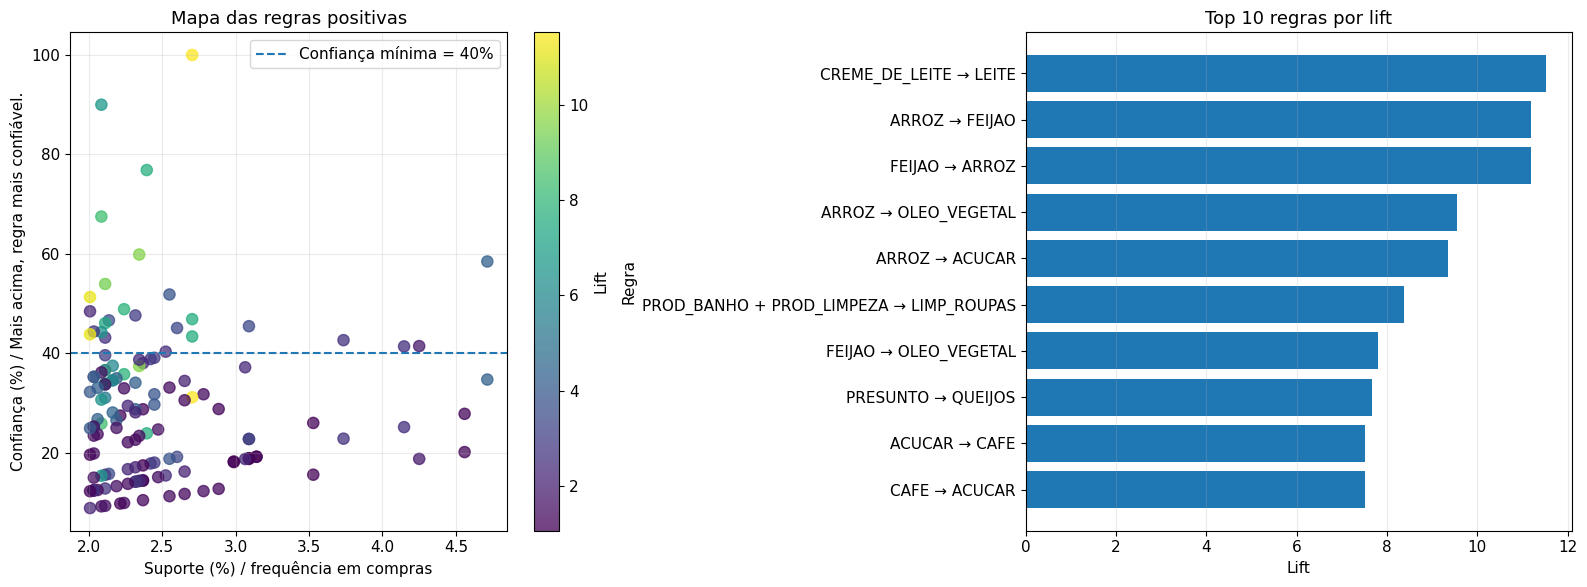

In [11]:
# ============================================================
# 7. VISUALIZAÇÃO DAS REGRAS
# ============================================================

regras_positivas = regras[
    regras["lift"] > 1
].copy()

top10_lift = regras_selecionadas.head(10).copy()

top10_lift["regra"] = (
    top10_lift["antecedente"]
    + " → "
    + top10_lift["consequente"]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ------------------------------------------------------------
# Gráfico 1 — Suporte × Confiança × Lift
# ------------------------------------------------------------

pontos = axes[0].scatter(
    regras_positivas["suporte_percentual"],
    regras_positivas["confianca_percentual"],
    c=regras_positivas["lift"],
    s=65,
    alpha=0.75
)

axes[0].axhline(
    y=min_confidence * 100,
    linestyle="--",
    label="Confiança mínima = 40%"
)

axes[0].set_title("Mapa das regras positivas")
axes[0].set_xlabel("Suporte (%) / frequência em compras")
axes[0].set_ylabel("Confiança (%) / Mais acima, regra mais confiável.")
axes[0].grid(alpha=0.25)
axes[0].legend()

barra_lift = fig.colorbar(pontos, ax=axes[0])
barra_lift.set_label("Lift")

# ------------------------------------------------------------
# Gráfico 2 — Top 10 por lift
# ------------------------------------------------------------

top10_grafico = top10_lift.sort_values("lift")

axes[1].barh(
    top10_grafico["regra"],
    top10_grafico["lift"]
)

axes[1].set_title("Top 10 regras por lift")
axes[1].set_xlabel("Lift")
axes[1].set_ylabel("Regra")
axes[1].grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()




A bolinha com 100% de confiança significa que, nessa regra, toda vez que o antecedente apareceu, o consequente também apareceu. Mas... O interessante é considerar as três dimensões:

frequência suficiente (suporte) + boa confiança + associação positiva (lift > 1).

**mais à direita** → maior suporte, portanto maior presença na base;  
**mais acima** → maior confiança;  
**maior valor na escala de lift** → associação proporcionalmente mais forte.

**Suporte, confiança e lift são complementares**.

# 9. Conclusão

Partimos de **3.882 transações e 132 produtos** e construímos a análise de forma incremental:

### Caminho percorrido

**Validação → exploração → suporte → Apriori → verificação adicional com FP-Growth → itemsets → regras → confiança/lift → interpretação**

O suporte mínimo de **2%** foi escolhido após comparar diferentes limites. Esse valor resultou em **122 itemsets frequentes**.

A validação com FP-Growth encontrou o mesmo conjunto de 122 itemsets, reforçando a consistência da mineração.

Os itemsets eram formados principalmente por produtos isolados e pares:

- 51 itemsets de 1 produto;
- 70 itemsets de 2 produtos;
- 1 itemset de 3 produtos.

As regras foram então avaliadas por **suporte, confiança e lift**.

Com os critérios:

### **suporte ≥ 2% · confiança ≥ 40% · lift > 1**

o conjunto foi reduzido para **26 regras**.

### Principal aprendizado

**Nenhuma métrica deve ser interpretada isoladamente.**

- suporte mostra a representatividade do padrão;
- confiança mostra a força direcional da regra;
- lift mostra se a associação supera o esperado pela frequência normal dos produtos.

Do ponto de vista comercial, os padrões encontrados podem apoiar análises de **venda cruzada, promoções combinadas e organização de produtos**.

Essas possibilidades devem ser tratadas como aplicações potenciais dos padrões observados, e não como prova de relação causal entre as compras.

In [10]:
# ============================================================
# 8. REGRAS DE DESTAQUE
# ============================================================

pares_destaque = [
    ("CREME_DE_LEITE", "LEITE"),
    ("ARROZ", "FEIJAO"),
    ("ARROZ", "OLEO_VEGETAL"),
    ("PRESUNTO", "QUEIJOS"),
    ("LIMP_ROUPAS", "PROD_LIMPEZA")
]

mascara = pd.Series(False, index=regras_selecionadas.index)

for antecedente, consequente in pares_destaque:
    mascara |= (
        (regras_selecionadas["antecedente"] == antecedente) &
        (regras_selecionadas["consequente"] == consequente)
    )

regras_destaque = regras_selecionadas[mascara].copy()

regras_destaque = regras_destaque[
    [
        "antecedente",
        "consequente",
        "suporte_percentual",
        "confianca_percentual",
        "lift"
    ]
].sort_values("lift", ascending=False)

display(regras_destaque.round(2))

,antecedente,consequente,suporte_percentual,confianca_percentual,lift
0,CREME_DE_LEITE,LEITE,2.70,100.00,11.52
1,ARROZ,FEIJAO,2.01,51.32,11.19
3,ARROZ,OLEO_VEGETAL,2.34,59.87,9.56
7,PRESUNTO,QUEIJOS,2.40,76.86,7.67
13,LIMP_ROUPAS,PROD_LIMPEZA,4.71,58.47,4.31


### Leitura das regras de destaque

**CREME_DE_LEITE → LEITE**  
Apresenta o maior lift entre as regras destacadas e confiança muito elevada. Na base analisada, LEITE aparece com frequência muito maior nas transações que contêm CREME_DE_LEITE do que seria esperado pela frequência geral de LEITE.

**ARROZ → FEIJAO**  
Mostra associação forte entre produtos tradicionalmente consumidos em conjunto.

**ARROZ → OLEO_VEGETAL**  
Também apresenta associação positiva elevada, compatível com um padrão de preparação de refeições.

**PRESUNTO → QUEIJOS**  
Destaca-se pela confiança elevada, indicando forte presença conjunta.

**LIMP_ROUPAS → PROD_LIMPEZA**  
Tem lift menor que algumas regras anteriores, mas suporte mais elevado. É um exemplo importante de por que as três métricas devem ser analisadas conjuntamente.

> **As regras representam coocorrência e associação na base analisada. Elas não demonstram causalidade.**